In [3]:
print("Hello Data Analyst!")

Hello Data Analyst!


In [1]:
import pandas as pd

In [2]:
import pandas as pd

# 1. Data Understanding

In [3]:
df = pd.read_csv("../data/raw/retail_store_sales.csv") 

In [5]:
df.head() 

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [9]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB


In [10]:
df.shape 

(12575, 11)

In [11]:
df.columns 

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

In [12]:
df.describe() 

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


In [13]:
df.isnull().sum() 

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [14]:
df[df.isnull().any(axis=1)] 

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
14,TXN_2490363,CUST_09,Milk Products,Item_16_MILK,27.5,2.0,55.0,Digital Wallet,Online,2022-05-22,NaN
...,...,...,...,...,...,...,...,...,...,...,...
12564,TXN_2153066,CUST_17,Electric household essentials,NaN,29.0,NaN,NaN,Digital Wallet,In-store,2024-03-28,False
12568,TXN_1096134,CUST_06,Food,Item_4_FOOD,9.5,8.0,76.0,Digital Wallet,In-store,2022-06-11,NaN
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN


In [15]:
df["Check"] = df["Price Per Unit"] * df["Quantity"] 

In [16]:
df[["Price Per Unit","Quantity","Total Spent","Check"]].head(10) 

,Price Per Unit,Quantity,Total Spent,Check
0,18.5,10.0,185.0,185.0
1,29.0,9.0,261.0,261.0
2,21.5,2.0,43.0,43.0
3,27.5,9.0,247.5,247.5
4,12.5,7.0,87.5,87.5
5,NaN,10.0,200.0,NaN
6,5.0,8.0,40.0,40.0
7,33.5,NaN,NaN,NaN
8,27.5,1.0,27.5,27.5
9,36.5,3.0,109.5,109.5


# 2. Data Cleaning

In [4]:
df_clean = df.copy() 

In [18]:
df_clean[df_clean["Price Per Unit"].isnull()][
    ["Quantity", "Total Spent"]
].head(10) 

,Quantity,Total Spent
5,10.0,200.0
11,8.0,52.0
17,10.0,275.0
21,3.0,105.0
32,8.0,196.0
127,10.0,275.0
159,9.0,126.0
216,8.0,40.0
247,7.0,150.5
271,9.0,99.0


In [20]:
df_clean.loc[
    df_clean["Price Per Unit"].isnull(),
    "Price Per Unit"
] = df_clean["Total Spent"] / df_clean["Quantity"] 

In [21]:
df_clean["Price Per Unit"].isnull().sum() 

np.int64(0)

In [22]:
df_clean.loc[
    df_clean["Quantity"].isnull(),
    "Quantity"
] = df_clean["Total Spent"] / df_clean["Price Per Unit"] 

In [23]:
df_clean["Quantity"].isnull().sum() 

np.int64(604)

In [24]:
df_clean[df_clean["Quantity"].isnull()][
    ["Price Per Unit", "Quantity", "Total Spent"]
].head(10) 

,Price Per Unit,Quantity,Total Spent
7,33.5,NaN,NaN
15,24.5,NaN,NaN
19,35.0,NaN,NaN
25,39.5,NaN,NaN
34,23.0,NaN,NaN
83,15.5,NaN,NaN
112,20.0,NaN,NaN
114,39.5,NaN,NaN
118,27.5,NaN,NaN
138,35.0,NaN,NaN


In [25]:
df_clean[
    df_clean["Quantity"].isnull() &
    df_clean["Total Spent"].isnull()
].shape 

(604, 12)

In [26]:
df_clean = df_clean.dropna(
    subset=["Quantity", "Total Spent"]
) 

In [27]:
df_clean.shape 

(11971, 12)

In [28]:
df_clean.isnull().sum() 

Transaction ID         0
Customer ID            0
Category               0
Item                 609
Price Per Unit         0
Quantity               0
Total Spent            0
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    3988
Check                609
dtype: int64

In [9]:
df_clean.isnull().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [10]:
df_clean.loc[
    df_clean["Price Per Unit"].isnull(),
    "Price Per Unit"
] = df_clean["Total Spent"] / df_clean["Quantity"]

In [11]:
df_clean["Price Per Unit"].isnull().sum()

np.int64(0)

In [12]:
df_clean.loc[
    df_clean["Quantity"].isnull(),
    "Quantity"
] = df_clean["Total Spent"] / df_clean["Price Per Unit"]

In [13]:
df_clean["Quantity"].isnull().sum()

np.int64(604)

In [14]:
df_clean.loc[
    df_clean["Quantity"].isnull(),
    ["Price Per Unit", "Quantity", "Total Spent"]
].head(10)

,Price Per Unit,Quantity,Total Spent
7,33.5,NaN,NaN
15,24.5,NaN,NaN
19,35.0,NaN,NaN
25,39.5,NaN,NaN
34,23.0,NaN,NaN
83,15.5,NaN,NaN
112,20.0,NaN,NaN
114,39.5,NaN,NaN
118,27.5,NaN,NaN
138,35.0,NaN,NaN


In [15]:
df_clean = df_clean.dropna(
    subset=["Quantity", "Total Spent"]
)

In [16]:
df_clean.shape

(11971, 11)

In [17]:
df_clean["Item"].isnull().sum()

np.int64(609)

In [18]:
df_clean["Item"] = df_clean["Item"].fillna("Unknown")

In [19]:
df_clean["Item"].isnull().sum()

np.int64(0)

In [20]:
df_clean["Discount Applied"].value_counts(dropna=False)

Discount Applied
True     4019
NaN      3988
False    3964
Name: count, dtype: int64

In [21]:
df_clean.isnull().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                   0
Price Per Unit         0
Quantity               0
Total Spent            0
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    3988
dtype: int64

In [22]:
df_clean["Quantity"].describe()

count    11971.000000
mean         5.536380
std          2.857883
min          1.000000
25%          3.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: Quantity, dtype: float64

# 3. Data Validation

In [23]:
df_clean["Price Per Unit"].describe()

count    11971.000000
mean        23.360872
std         10.741889
min          5.000000
25%         14.000000
50%         23.000000
75%         33.500000
max         41.000000
Name: Price Per Unit, dtype: float64

In [24]:
df_clean["Price Per Unit"].value_counts().sort_index()

Price Per Unit
5.0     426
6.5     519
8.0     380
9.5     402
11.0    500
12.5    524
14.0    438
15.5    560
17.0    332
18.5    288
20.0    630
21.5    621
23.0    516
24.5    435
26.0    509
27.5    496
29.0    548
30.5    359
32.0    469
33.5    678
35.0    366
36.5    451
38.0    547
39.5    381
41.0    596
Name: count, dtype: int64

In [25]:
df_clean["Total Spent"].describe()

count    11971.000000
mean       129.652577
std         94.750697
min          5.000000
25%         51.000000
50%        108.500000
75%        192.000000
max        410.000000
Name: Total Spent, dtype: float64

In [26]:
check = (
    df_clean["Price Per Unit"] * df_clean["Quantity"]
    == df_clean["Total Spent"]
)

check.value_counts()

True    11971
Name: count, dtype: int64

In [27]:
check = (
    df_clean["Price Per Unit"] * df_clean["Quantity"]
    == df_clean["Total Spent"]
)

In [28]:
df_clean["Transaction Date"].dtype

<StringDtype(storage='python', na_value=nan)>

In [29]:
df_clean["Transaction Date"].head()

0    2024-04-08
1    2023-07-23
2    2022-10-05
3    2022-05-07
4    2022-10-02
Name: Transaction Date, dtype: str

# 4 Data Preparation

In [30]:
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"]
)

In [ ]:
df_clean["Transaction Date"].dtype

# 5 EDA

In [32]:
df_clean["Transaction Date"].dt.year

0        2024
1        2023
2        2022
3        2022
4        2022
         ... 
12570    2023
12571    2022
12572    2024
12573    2023
12574    2022
Name: Transaction Date, Length: 11971, dtype: int32

In [ ]:
# Validasi: mengecek rentang tanggal transaksi
# untuk memastikan periode data yang tersedia
# sebelum digunakan dalam analisis waktu.

In [33]:
df_clean["Transaction Date"].min(), df_clean["Transaction Date"].max()

(Timestamp('2022-01-01 00:00:00'), Timestamp('2025-01-18 00:00:00'))

In [ ]:
# Validasi: mengecek nilai kosong pada Transaction Date

In [34]:
df_clean["Transaction Date"].isnull().sum()

np.int64(0)

## 5.1 Analisis Category

In [35]:
df_clean["Category"].value_counts()

Category
Furniture                             1525
Electric household essentials         1516
Milk Products                         1513
Food                                  1507
Butchers                              1496
Beverages                             1496
Computers and electric accessories    1477
Patisserie                            1441
Name: count, dtype: int64

In [36]:
df_clean["Category"].value_counts(normalize=True) * 100

Category
Furniture                             12.739120
Electric household essentials         12.663938
Milk Products                         12.638877
Food                                  12.588756
Butchers                              12.496867
Beverages                             12.496867
Computers and electric accessories    12.338151
Patisserie                            12.037424
Name: proportion, dtype: float64

In [37]:
df_clean.groupby("Category")["Total Spent"].sum().sort_values(ascending=False)

Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Total Spent, dtype: float64

In [12]:
df_clean.groupby("Category")["Total Spent"].mean().sort_values(ascending=False)

Category
Butchers                              139.116310
Electric household essentials         134.441623
Beverages                             131.716243
Food                                  129.271400
Computers and electric accessories    129.107989
Furniture                             128.072131
Patisserie                            126.416031
Milk Products                         119.042961
Name: Total Spent, dtype: float64

## 5.2 Analisis Item 

In [13]:
df_clean["Item"].value_counts().head(10)

Item
Item_2_BEV      126
Item_25_FUR     113
Item_11_FUR     110
Item_16_MILK    109
Item_1_MILK     109
Item_20_BUT     107
Item_5_FUR      107
Item_14_FOOD    106
Item_11_MILK    106
Item_19_CEA     106
Name: count, dtype: int64

In [14]:
df_clean.groupby("Item")["Total Spent"].sum().sort_values(ascending=False).head(10)

Item
Item_25_FUR     25256.0
Item_25_EHE     23083.0
Item_25_BUT     21894.0
Item_24_FUR     21172.0
Item_25_FOOD    20541.0
Item_22_BUT     19710.0
Item_23_BUT     19114.0
Item_20_BUT     18860.5
Item_19_MILK    18848.0
Item_23_EHE     18468.0
Name: Total Spent, dtype: float64

In [15]:
df_clean.groupby("Item")["Total Spent"].mean().sort_values(ascending=False).head(10)

Item
Item_24_CEA     265.214286
Item_25_MILK    251.125000
Item_24_BEV     240.646154
Item_24_MILK    236.036585
Item_25_EHE     235.540816
Item_24_BUT     233.238095
Item_25_FOOD    230.797753
Item_25_CEA     229.600000
Item_25_BEV     228.128205
Item_21_BEV     227.093023
Name: Total Spent, dtype: float64

In [16]:
df_clean.groupby("Item")["Quantity"].sum().sort_values(ascending=False).head(10)

Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64

## 5.3 Analisis Payment Method

In [17]:
df_clean["Payment Method"].value_counts()

Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

In [18]:
df_clean.groupby("Payment Method")["Total Spent"].sum().sort_values(
    ascending=False
)

Payment Method
Cash              537710.0
Digital Wallet    507279.0
Credit Card       507082.0
Name: Total Spent, dtype: float64

In [19]:
df_clean.groupby("Payment Method")["Total Spent"].mean().sort_values(
    ascending=False
)

Payment Method
Cash              131.052888
Credit Card       129.127069
Digital Wallet    128.718346
Name: Total Spent, dtype: float64

## 5.4 Analisis Location

In [20]:
df_clean["Location"].value_counts()

Location
Online      6354
In-store    6221
Name: count, dtype: int64

In [21]:
df_clean.groupby("Location")["Total Spent"].sum().sort_values(
    ascending=False
)

Location
Online      791401.0
In-store    760670.0
Name: Total Spent, dtype: float64

In [22]:
df_clean.groupby("Location")["Total Spent"].mean().sort_values(
    ascending=False
)

Location
Online      130.422050
In-store    128.861596
Name: Total Spent, dtype: float64

In [26]:
df_clean.groupby(
    df_clean["Transaction Date"].dt.year
)["Total Spent"].sum()

Transaction Date
2022    510329.5
2023    491312.0
2024    524881.0
2025     25548.5
Name: Total Spent, dtype: float64

In [24]:
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"]
)

In [25]:
df_clean["Transaction Date"].dtype

dtype('<M8[us]')

In [27]:
df_clean.groupby(
    df_clean["Transaction Date"].dt.year
)["Total Spent"].sum()

Transaction Date
2022    510329.5
2023    491312.0
2024    524881.0
2025     25548.5
Name: Total Spent, dtype: float64

In [28]:
df_clean.groupby(
    df_clean["Transaction Date"].dt.year
)["Transaction ID"].count()

Transaction Date
2022    4134
2023    3987
2024    4241
2025     213
Name: Transaction ID, dtype: int64

In [29]:
df_clean.groupby(
    df_clean["Transaction Date"].dt.to_period("M")
)["Total Spent"].sum()

Transaction Date
2022-01    52911.5
2022-02    43325.5
2022-03    40996.0
2022-04    40442.0
2022-05    40347.5
2022-06    42576.0
2022-07    44471.5
2022-08    41333.5
2022-09    46113.5
2022-10    38355.0
2022-11    41256.5
2022-12    38201.0
2023-01    48052.5
2023-02    39214.5
2023-03    38534.5
2023-04    38905.5
2023-05    40480.5
2023-06    42474.0
2023-07    45632.5
2023-08    38592.0
2023-09    41069.0
2023-10    38322.0
2023-11    37014.0
2023-12    43021.0
2024-01    47908.5
2024-02    37145.0
2024-03    42861.5
2024-04    46271.0
2024-05    43766.5
2024-06    44721.0
2024-07    41405.0
2024-08    43362.0
2024-09    42161.5
2024-10    42736.5
2024-11    44076.0
2024-12    48466.5
2025-01    25548.5
Freq: M, Name: Total Spent, dtype: float64

In [30]:
monthly_sales = df_clean.groupby(
    df_clean["Transaction Date"].dt.to_period("M")
)["Total Spent"].sum()

monthly_sales.sort_values(ascending=False).head()

Transaction Date
2022-01    52911.5
2024-12    48466.5
2023-01    48052.5
2024-01    47908.5
2024-04    46271.0
Freq: M, Name: Total Spent, dtype: float64

In [3]:
monthly_transactions = df_clean.groupby(
    df_clean["Transaction Date"].dt.to_period("M")
)["Transaction ID"].count()

monthly_transactions.sort_values(ascending=False).head()

NameError: name 'df_clean' is not defined

## 5.6 Analisis Quantity

In [5]:
df_clean["Quantity"].value_counts().sort_index()

Quantity
1.0     1147
2.0     1164
3.0     1224
4.0     1155
5.0     1228
6.0     1220
7.0     1227
8.0     1226
9.0     1148
10.0    1232
Name: count, dtype: int64

In [6]:
quantity_spending = df_clean.groupby(
    "Quantity"
)["Total Spent"].mean()

quantity_spending

Quantity
1.0      23.278553
2.0      46.347938
3.0      68.750000
4.0      94.670130
5.0     118.059853
6.0     139.977049
7.0     162.189487
8.0     186.280587
9.0     209.975174
10.0    238.425325
Name: Total Spent, dtype: float64

In [7]:
df_clean["Discount Applied"].value_counts(dropna=False)

Discount Applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64

In [8]:
df_clean[df_clean["Discount Applied"].notna()].groupby(
    "Discount Applied"
)["Total Spent"].mean()

Discount Applied
False    129.953330
True     130.491043
Name: Total Spent, dtype: float64

In [9]:
df_clean[df_clean["Discount Applied"].notna()].groupby(
    "Discount Applied"
)["Total Spent"].sum()

Discount Applied
False    515135.0
True     524443.5
Name: Total Spent, dtype: float64

In [10]:
discount_summary = df_clean[df_clean["Discount Applied"].notna()].groupby(
    "Discount Applied"
).agg(
    Jumlah_Transaksi=("Total Spent", "count"),
    Total_Penjualan=("Total Spent", "sum"),
    Rata_Rata_Transaksi=("Total Spent", "mean")
)

discount_summary

,Jumlah_Transaksi,Total_Penjualan,Rata_Rata_Transaksi
Discount Applied,,,
False,3964,515135.0,129.953330
True,4019,524443.5,130.491043


In [11]:
df_clean["Customer ID"].nunique()

25

In [12]:
customer_transactions = df_clean["Customer ID"].value_counts()

customer_transactions.head(10)

Customer ID
CUST_05    544
CUST_24    543
CUST_13    534
CUST_08    533
CUST_09    519
CUST_15    519
CUST_16    515
CUST_23    513
CUST_01    507
CUST_18    507
Name: count, dtype: int64

In [13]:
customer_spending = df_clean.groupby("Customer ID")["Total Spent"].sum()

customer_spending.sort_values(ascending=False).head(10)

Customer ID
CUST_24    68452.0
CUST_08    67351.5
CUST_05    66974.5
CUST_16    65570.5
CUST_13    65037.0
CUST_23    64507.0
CUST_10    63155.5
CUST_15    63117.5
CUST_21    62933.0
CUST_02    62046.5
Name: Total Spent, dtype: float64

In [14]:
customer_avg_spending = df_clean.groupby("Customer ID")["Total Spent"].mean()

customer_avg_spending.sort_values(ascending=False).head(10)

Customer ID
CUST_03    136.347534
CUST_04    135.752747
CUST_23    134.110187
CUST_19    133.035011
CUST_02    132.861884
CUST_08    132.843195
CUST_16    132.733806
CUST_21    132.212185
CUST_24    131.892100
CUST_07    131.658351
Name: Total Spent, dtype: float64

In [15]:
customer_summary = df_clean.groupby("Customer ID").agg(
    Jumlah_Transaksi=("Total Spent", "count"),
    Total_Spent=("Total Spent", "sum"),
    Rata_Rata_Transaksi=("Total Spent", "mean")
)

customer_summary.sort_values(
    "Total_Spent",
    ascending=False
).head(10)

,Jumlah_Transaksi,Total_Spent,Rata_Rata_Transaksi
Customer ID,,,
CUST_24,519,68452.0,131.892100
CUST_08,507,67351.5,132.843195
CUST_05,516,66974.5,129.795543
CUST_16,494,65570.5,132.733806
CUST_13,508,65037.0,128.025591
CUST_23,481,64507.0,134.110187
CUST_10,481,63155.5,131.300416
CUST_15,501,63117.5,125.983034
CUST_21,476,62933.0,132.212185


In [16]:
customer_summary.describe()

,Jumlah_Transaksi,Total_Spent,Rata_Rata_Transaksi
count,25.000000,25.000000,25.000000
mean,478.840000,62082.840000,129.685023
std,20.705635,2933.820681,3.815533
min,446.000000,57155.500000,121.095876
25%,461.000000,60694.500000,127.012222
50%,478.000000,61533.000000,129.888412
75%,494.000000,63155.500000,132.733806
max,519.000000,68452.000000,136.347534


Matplotlib is building the font cache; this may take a moment.


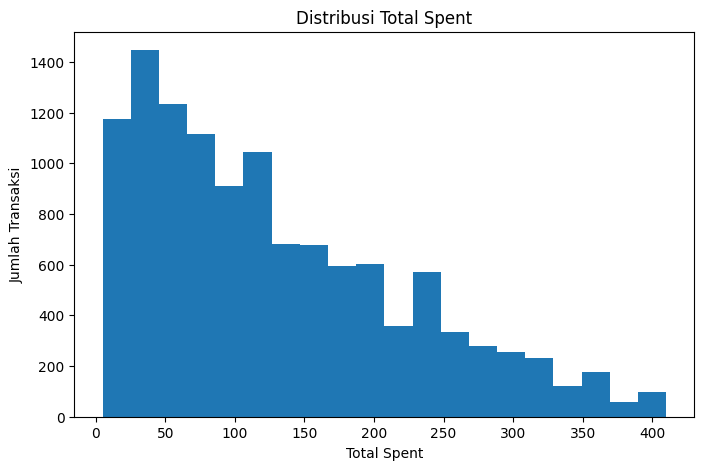

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean["Total Spent"], bins=20)

plt.title("Distribusi Total Spent")
plt.xlabel("Total Spent")
plt.ylabel("Jumlah Transaksi")

plt.show()

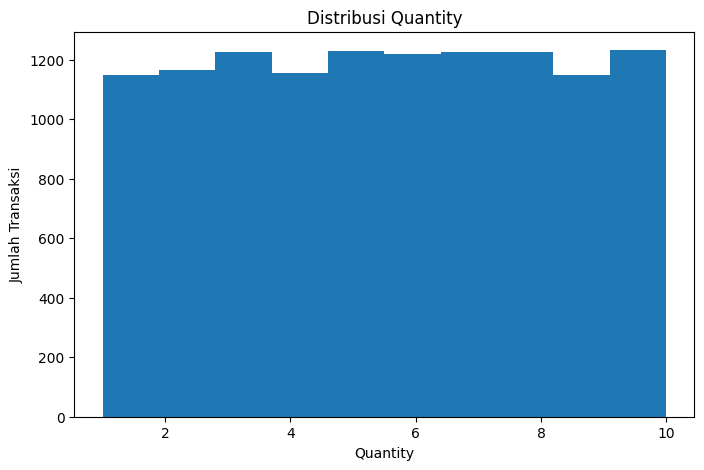

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean["Quantity"], bins=10)

plt.title("Distribusi Quantity")
plt.xlabel("Quantity")
plt.ylabel("Jumlah Transaksi")

plt.show()

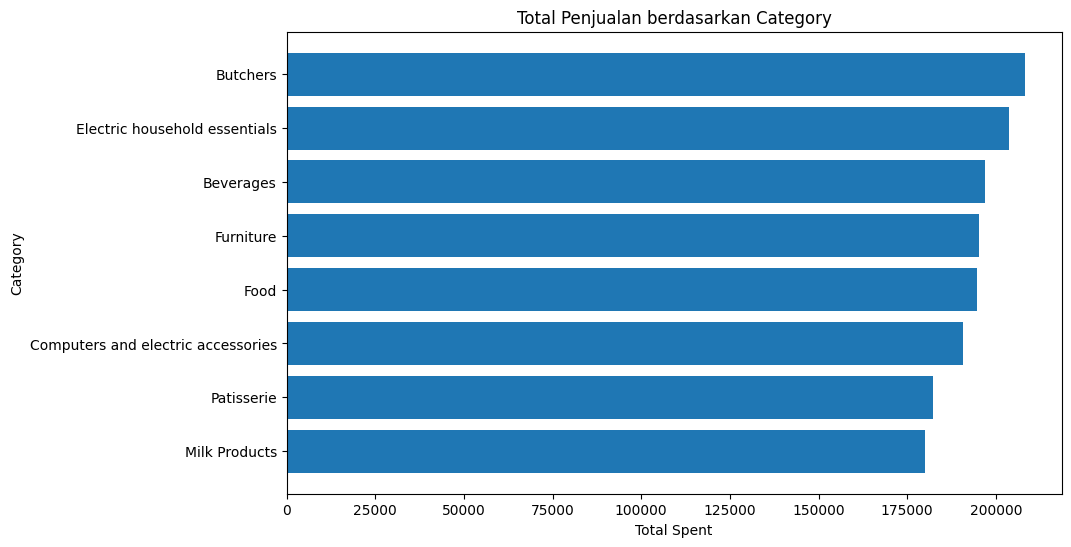

In [19]:
category_sales = df_clean.groupby("Category")["Total Spent"].sum().sort_values()

plt.figure(figsize=(10, 6))

plt.barh(category_sales.index, category_sales.values)

plt.title("Total Penjualan berdasarkan Category")
plt.xlabel("Total Spent")
plt.ylabel("Category")

plt.show()

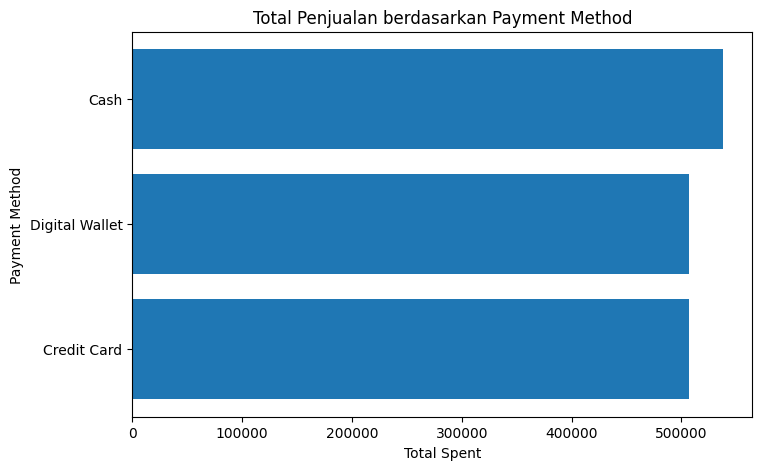

In [20]:
payment_sales = df_clean.groupby("Payment Method")["Total Spent"].sum().sort_values()

plt.figure(figsize=(8, 5))

plt.barh(payment_sales.index, payment_sales.values)

plt.title("Total Penjualan berdasarkan Payment Method")
plt.xlabel("Total Spent")
plt.ylabel("Payment Method")

plt.show()

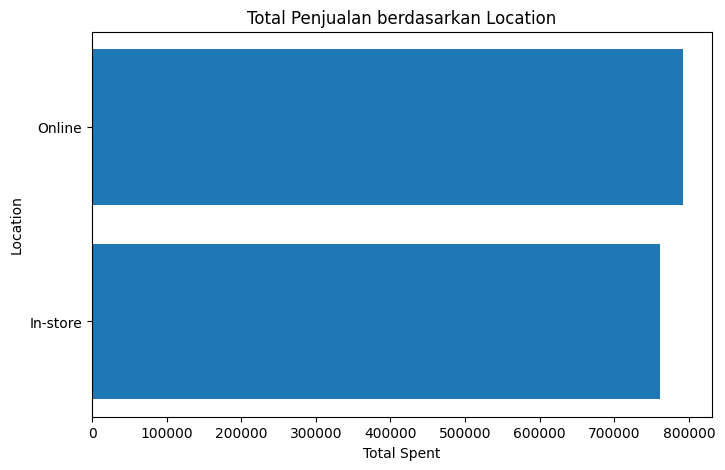

In [21]:
location_sales = df_clean.groupby("Location")["Total Spent"].sum().sort_values()

plt.figure(figsize=(8, 5))

plt.barh(location_sales.index, location_sales.values)

plt.title("Total Penjualan berdasarkan Location")
plt.xlabel("Total Spent")
plt.ylabel("Location")

plt.show()

## 5.5 Analisis Transaction Date

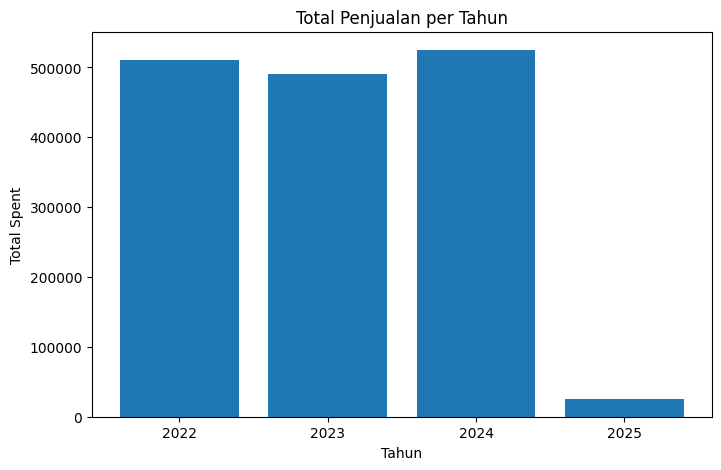

In [25]:
yearly_sales = df_clean.groupby(
    df_clean["Transaction Date"].dt.year
)["Total Spent"].sum()

plt.figure(figsize=(8, 5))

plt.bar(yearly_sales.index.astype(str), yearly_sales.values)

plt.title("Total Penjualan per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Total Spent")

plt.show()

In [23]:
df_clean["Transaction Date"].dtype

<StringDtype(storage='python', na_value=nan)>

In [24]:
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"]
)

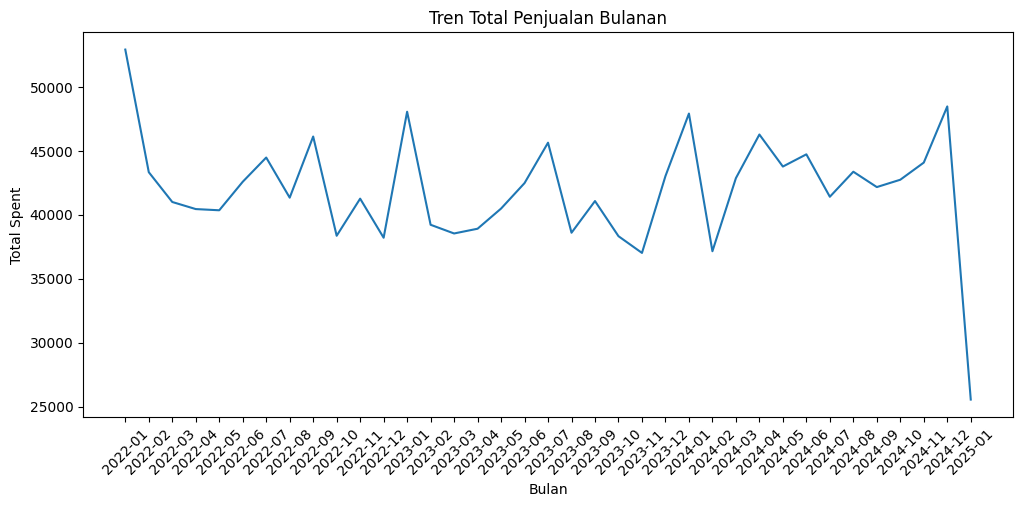

In [26]:
monthly_sales = df_clean.groupby(
    df_clean["Transaction Date"].dt.to_period("M")
)["Total Spent"].sum()

plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title("Tren Total Penjualan Bulanan")
plt.xlabel("Bulan")
plt.ylabel("Total Spent")

plt.xticks(rotation=45)

plt.show()

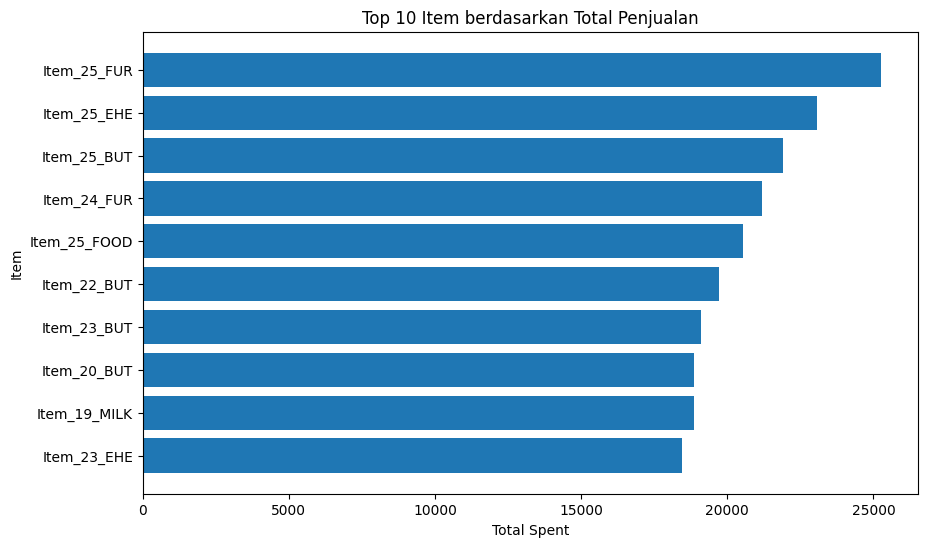

In [27]:
item_sales = df_clean.groupby("Item")["Total Spent"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

plt.barh(item_sales.index[::-1], item_sales.values[::-1])

plt.title("Top 10 Item berdasarkan Total Penjualan")
plt.xlabel("Total Spent")
plt.ylabel("Item")

plt.show()

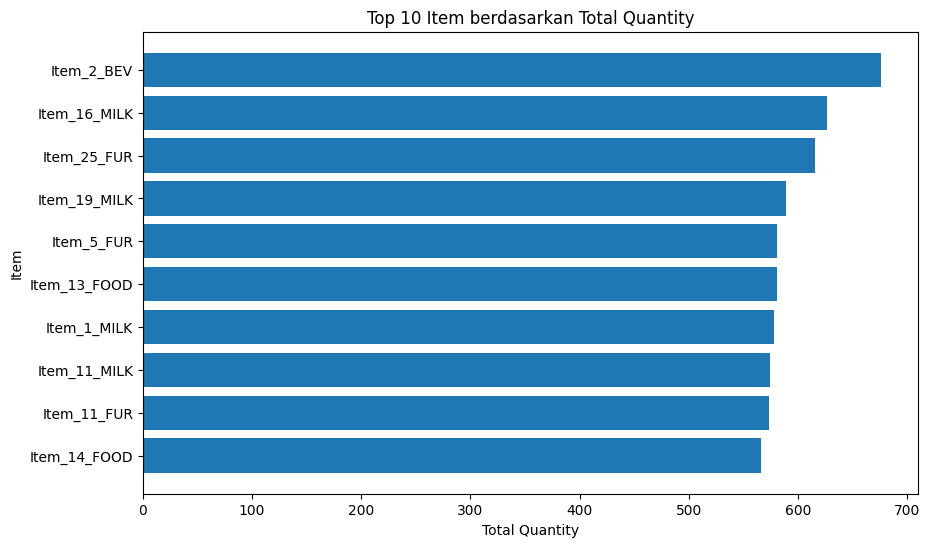

In [28]:
item_quantity = df_clean.groupby("Item")["Quantity"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

plt.barh(item_quantity.index[::-1], item_quantity.values[::-1])

plt.title("Top 10 Item berdasarkan Total Quantity")
plt.xlabel("Total Quantity")
plt.ylabel("Item")

plt.show()

## 5.9 EDA Insights

### 5.9.1 Category

- Kategori **Butchers** memiliki total penjualan tertinggi sebesar **208.118**.
- Kategori **Milk Products** memiliki total penjualan terendah sebesar **180.112**.
- Meskipun terdapat perbedaan, total penjualan antar kategori relatif berdekatan.

**Insight:**
Performa penjualan antar kategori cukup merata, meskipun Butchers memiliki kontribusi penjualan tertinggi.

### 5.9.2 Item

- **Item_25_FUR** memiliki total penjualan tertinggi sebesar **25.256**.
- **Item_2_BEV** memiliki total quantity tertinggi sebesar **676 unit**.
- Item dengan jumlah unit terjual terbanyak berbeda dengan item yang memiliki total penjualan terbesar.

**Insight:**
Volume penjualan dan nilai penjualan merupakan dua metrik yang berbeda. Item dengan jumlah unit terjual lebih banyak belum tentu menghasilkan total penjualan yang lebih tinggi karena harga per unit juga memengaruhi Total Spent.

### 5.9.3 Payment Method

- **Cash** memiliki total penjualan tertinggi sebesar **537.710**.
- Digital Wallet memiliki total penjualan sebesar **507.279**.
- Credit Card memiliki total penjualan sebesar **507.082**.
- Digital Wallet dan Credit Card memiliki total penjualan yang hampir sama.

**Insight:**
Cash menjadi metode pembayaran dengan total penjualan terbesar. Namun, perbedaan total penjualan juga berkaitan dengan jumlah transaksi masing-masing metode pembayaran.

### 5.9.4 Location

- Transaksi **Online** menghasilkan total penjualan sebesar **791.401**.
- Transaksi **In-store** menghasilkan total penjualan sebesar **760.670**.
- Online memiliki jumlah transaksi yang sedikit lebih banyak dibandingkan In-store.
- Rata-rata nilai transaksi Online (**130,42**) dan In-store (**128,86**) relatif berdekatan.

**Insight:**
Penjualan Online sedikit lebih tinggi dibandingkan In-store, baik dari total penjualan maupun jumlah transaksi. Namun, rata-rata nilai transaksi kedua lokasi relatif berdekatan.

### 5.9.5 Customer

- Dataset memiliki **25 Customer ID unik**.
- **CUST_05** memiliki jumlah transaksi terbanyak, yaitu **544 transaksi**.
- **CUST_24** memiliki total pengeluaran tertinggi sebesar **68.452**.
- **CUST_03** memiliki rata-rata nilai transaksi tertinggi sebesar **136,35**.

**Insight:**
Customer dengan jumlah transaksi terbanyak tidak selalu memiliki total pengeluaran atau rata-rata nilai transaksi tertinggi. Oleh karena itu, performa customer perlu dilihat menggunakan beberapa metrik, seperti frekuensi transaksi, total pengeluaran, dan rata-rata nilai transaksi.

### 5.9.6 Quantity

- Quantity berada pada rentang **1–10 unit per transaksi**.
- Distribusi quantity relatif merata pada seluruh rentang tersebut.
- Quantity 10 memiliki jumlah transaksi terbanyak, yaitu **1.232 transaksi**.
- Quantity 1 memiliki jumlah transaksi paling sedikit, yaitu **1.147 transaksi**.

**Insight:**
Tidak terdapat quantity tertentu yang sangat dominan. Jumlah produk yang dibeli per transaksi tersebar relatif merata antara 1 hingga 10 unit.

### 5.9.7 Discount Applied

- Terdapat **4.019 transaksi** dengan discount.
- Terdapat **3.964 transaksi** tanpa discount.
- Total penjualan transaksi dengan discount sebesar **524.443,5**.
- Total penjualan transaksi tanpa discount sebesar **515.135**.
- Rata-rata nilai transaksi dengan discount (**130,49**) dan tanpa discount (**129,95**) relatif sama.
- Nilai `Discount Applied` yang kosong tidak digunakan dalam perbandingan.

**Insight:**
Transaksi dengan discount memiliki total penjualan sedikit lebih tinggi dibandingkan transaksi tanpa discount. Namun, rata-rata nilai transaksi keduanya relatif sama sehingga data ini belum cukup untuk menyimpulkan bahwa discount secara langsung meningkatkan nilai transaksi.

### 5.9.8 Transaction Date

- Data transaksi mencakup periode **1 Januari 2022 sampai 18 Januari 2025**.
- Total penjualan tertinggi pada periode satu tahun penuh terjadi pada **2024**, yaitu **524.881**.
- Total penjualan 2022 sebesar **510.329,5**.
- Total penjualan 2023 sebesar **491.312**.
- Data tahun 2025 hanya tersedia sampai **18 Januari**, sehingga tidak dibandingkan langsung dengan tahun penuh sebelumnya.
- Penjualan bulanan menunjukkan pola yang berfluktuasi dari waktu ke waktu.

**Insight:**
Penjualan tidak menunjukkan pola kenaikan atau penurunan yang konsisten setiap bulan. Tahun 2024 memiliki total penjualan tertinggi dibandingkan 2022 dan 2023.

### 5.9.9 Kesimpulan EDA

Berdasarkan Exploratory Data Analysis (EDA), beberapa temuan utama dari dataset Retail Sales adalah:

1. Penjualan antar kategori relatif merata, dengan **Butchers** memiliki total penjualan tertinggi.
2. **Item_25_FUR** memiliki total penjualan tertinggi, sedangkan **Item_2_BEV** memiliki jumlah unit terjual terbanyak.
3. **Cash** merupakan metode pembayaran dengan total penjualan terbesar.
4. Penjualan **Online** sedikit lebih tinggi dibandingkan In-store.
5. Aktivitas dari 25 customer relatif merata, tetapi customer dengan jumlah transaksi terbanyak tidak selalu memiliki total pengeluaran terbesar.
6. Quantity per transaksi tersebar relatif merata pada rentang 1–10 unit.
7. Transaksi dengan discount memiliki total penjualan sedikit lebih tinggi, tetapi rata-rata nilai transaksinya relatif sama dengan transaksi tanpa discount.
8. Tahun 2024 memiliki total penjualan tertinggi dibandingkan tahun penuh 2022 dan 2023.
9. Penjualan bulanan mengalami fluktuasi dan belum menunjukkan pola kenaikan atau penurunan yang konsisten.